Today's topics:
* plotting a function of two variables with `tricontourf`
* fitting a plane `z = a + b x + c y` with `minimize`
* reading the fitted coefficients

# 3D printed parts

A fused deposition printer builds a part from beads of melted plastic, one layer at a time.
The stacked beads leave steps on the side wall, so the side wall is rough to the touch.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/a/ad/RepRap_printing_closeup.jpg/960px-RepRap_printing_closeup.jpg" alt="Close-up of a fused-deposition printer in operation, with a brass nozzle above three red parts whose deposited layers are visible" width=420/>

*Photo by Emmanuel Gilloz, [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:RepRap_printing_closeup.jpg).*

Above: a [RepRap](https://en.wikipedia.org/wiki/RepRap) printer laying down the layers of three red parts.

Today's data come from Ahmet Okudan's [3D printer dataset](https://github.com/ahmetokudan/3dprinterdeeplearning), released for unrestricted use.
It's a different table from the compression test in L22 and L23.

It has 50 prints, each with the printer settings and the measured roughness of the side wall in microns ($\mu$m).

Two of the settings are `layer_height (mm)`, the thickness of one bead, and `wall_thickness (mm)`.
How much does each one change the roughness of the wall?

Let's load the table and convert layer height to $\mu$m, so it has the same units as roughness.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize

data = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/3dprinting.csv')

layer_um = data['layer_height (mm)'] * 1000  # um
wall = data['wall_thickness (mm)']           # mm
roughness = data['roughness (microns)']      # um
print(len(data), 'prints')

50 prints


Here's the same pair of settings, with roughness shown by shade.

Text(0, 0.5, 'wall thickness (mm)')

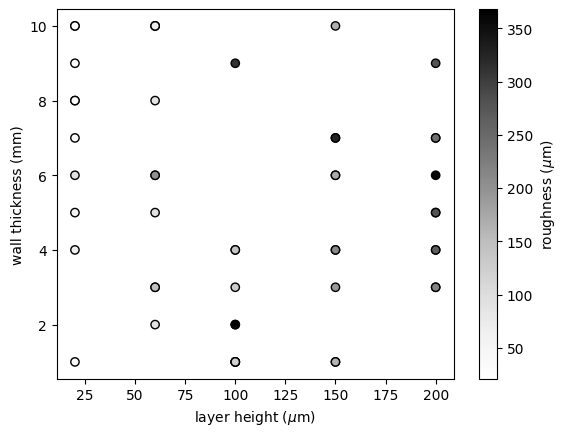

In [2]:
fig, ax = plt.subplots()
im = ax.scatter(layer_um, wall, c=roughness, cmap='Greys', edgecolor='k')
cb = fig.colorbar(im, ax=ax)
cb.set_label('roughness ($\\mu$m)')
ax.set_xlabel('layer height ($\\mu$m)')
ax.set_ylabel('wall thickness (mm)')

The markers get darker from left to right, and they hardly change from bottom to top.

We'd like a formula for how roughness changes with both settings in this table.
A plane has three numbers to find.

I like to practice on a surface where we already know them, so we can check the fit.

# A surface from a formula

A line has two parameters, $y = a + b x$.
A plane has three:

$$z = a + b\,x + c\,y$$

Here:
* $b$ is the change in $z$ per unit of $x$
* $c$ is the change in $z$ per unit of $y$
* $a$ is $z$ at $x = 0$ and $y = 0$

We'll use 25 points on a grid, with $x$ and $y$ from -1 to 1.

The collapsed cell holds the points and some measurement noise that we'll use in a bit.

In [3]:
#@title Provided points and measurement noise (click > to run) { display-mode: "form" }
x = np.array([-1, -0.5, 0, 0.5, 1] * 5)
y = np.array([-1] * 5 + [-0.5] * 5 + [0] * 5 + [0.5] * 5 + [1] * 5)
noise = np.array([0.3, -0.4, 0.1, 0.5, -0.2,
                  -0.5, 0.2, 0.4, -0.3, 0.1,
                  0.4, -0.1, -0.5, 0.3, 0.6,
                  -0.3, 0.5, -0.2, -0.6, 0.2,
                  0.1, -0.3, 0.5, 0.2, -0.4])

Let's make $z$ from a plane we choose, $z = 1 + x + 2y$.

In [4]:
def f(x, y):
    return 1 + x + 2 * y

z = f(x, y)

`tricontourf` fills the region between values of $z$ with shades, and we put the points on top.

Text(0, 0.5, 'y')

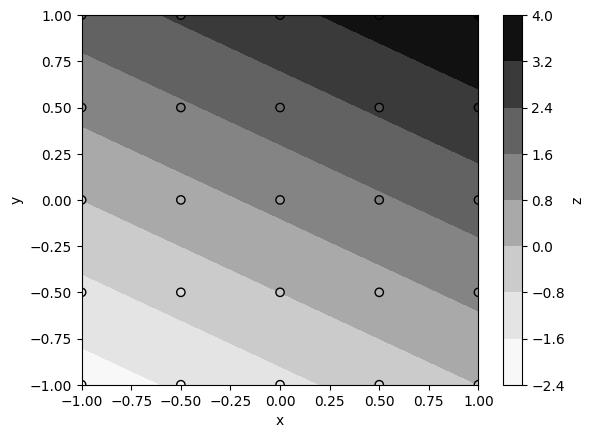

In [5]:
fig, ax = plt.subplots()
cs = ax.tricontourf(x, y, z, cmap='Greys')
ax.scatter(x, y, c=z, cmap='Greys', edgecolor='k')
cb = fig.colorbar(cs, ax=ax)
cb.set_label('z')
ax.set_xlabel('x')
ax.set_ylabel('y')

The bands of a plane are straight and parallel.
They're narrower going up than going right, because $z$ changes twice as fast with $y$.

# Fitting a plane with `minimize`

Now let's pretend we don't know $a$, $b$, and $c$, and fit them.
As with the exponential fit, we start by writing the model function, with the inputs first and the parameters after.

In [6]:
def plane(x, y, a, b, c):
    return a + b * x + c * y

The objective unpacks three parameters, builds the plane at every point, and returns the mean of the squared residuals.
The mean has the same lowest point as the sum, and the number stays small.

The arrays `x`, `y`, and `z` stay in the notebook, and the objective uses them from there.

In [7]:
def mse_plane(params):
    a, b, c = params
    residuals = z - plane(x, y, a, b, c)
    return np.mean(residuals**2)

At the true values the plane passes through every point, so the objective should be zero.
Let's try them, and a wrong guess for comparison.

In [8]:
print(mse_plane([1, 1, 2]))
print(mse_plane([0, 0, 0]))

0.0
3.5


`x0` has one starting value for each parameter, in the order of the unpack line.

In [9]:
res_exact = optimize.minimize(mse_plane, [1, 1, 1])
a_fit, b_fit, c_fit = res_exact.x
print(f'a = {a_fit:.3f}, b = {b_fit:.3f}, c = {c_fit:.3f}')
print(res_exact.success)

a = 1.000, b = 1.000, c = 2.000
True


With no noise, `minimize` recovers the plane exactly!

# Fitting noisy points

Measurements scatter around the shape underneath them.
Let's add the provided noise to $z$ and fit the same model again.

In [10]:
z = f(x, y) + noise
print(f'noise size (standard deviation) = {np.std(noise):.2f}')

noise size (standard deviation) = 0.36


In [11]:
res_noisy = optimize.minimize(mse_plane, [1, 1, 1])
a_fit, b_fit, c_fit = res_noisy.x
print(f'a = {a_fit:.3f}, b = {b_fit:.3f}, c = {c_fit:.3f}')

a = 1.024, b = 1.032, c = 1.972


The true values were 1, 1, and 2.

For the score we use the same `rmse` helper as in L23.

In [12]:
def rmse(y, y_fit):
    """Root-mean-square error, in the units of y."""
    return np.sqrt(np.mean((y - y_fit)**2))

z_fit = plane(x, y, *res_noisy.x)
print(f'RMSE = {rmse(z, z_fit):.2f}')

RMSE = 0.36


The fit absorbs part of the noise by shifting the three coefficients.
The remaining residuals have an RMSE close to the noise size.

Let's put the noisy points on the left and the fitted plane on the right.

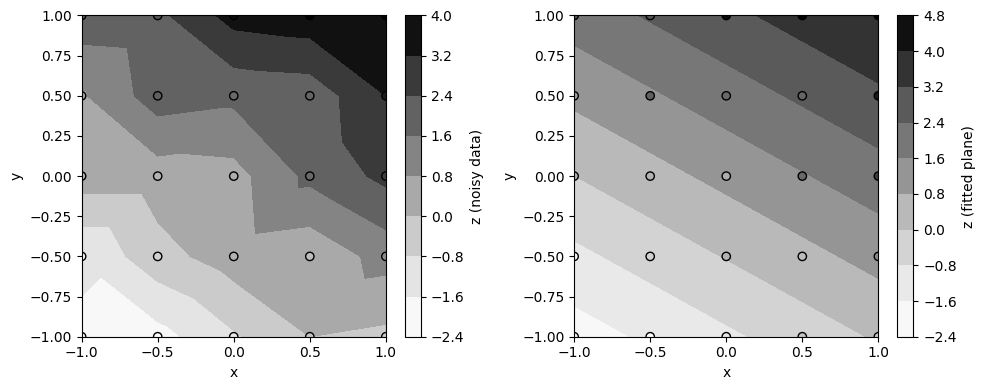

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ax = axes[0]
cs = ax.tricontourf(x, y, z, cmap='Greys')
ax.scatter(x, y, c=z, cmap='Greys', edgecolor='k')
cb = fig.colorbar(cs, ax=ax)
cb.set_label('z (noisy data)')
ax.set_xlabel('x')
ax.set_ylabel('y')

ax = axes[1]
cs = ax.tricontourf(x, y, z_fit, cmap='Greys')
ax.scatter(x, y, c=z, cmap='Greys', edgecolor='k')
cb = fig.colorbar(cs, ax=ax)
cb.set_label('z (fitted plane)')
ax.set_xlabel('x')
ax.set_ylabel('y')

fig.tight_layout()  # resize the panels so the labels don't overlap

The bands of the noisy points are uneven, and the bands of the fitted plane are straight again.

Now the printer data.
The objective is the same recipe, with `layer_um`, `wall`, and `roughness` in place of `x`, `y`, and `z`.

In [14]:
def mse_roughness(params):
    a, b, c = params
    residuals = roughness - plane(layer_um, wall, a, b, c)
    return np.mean(residuals**2)

### [Check your understanding]

1. Call `optimize.minimize(mse_roughness, [1, 1, 1])`.
   Unpack `res.x` into `a_fit, b_fit, c_fit`.
2. Print `a_fit`, `b_fit`, and `c_fit` with their units.
   Layer height is in $\mu$m, wall thickness is in mm, and roughness is in $\mu$m.
3. Use `plane` and `*res.x` to predict the roughness at a layer height of 100 $\mu$m and a wall thickness of 5 mm.

*Using the coefficients, which setting is associated with the larger roughness change across this table?*

Optional challenge: print `rmse(roughness, plane(layer_um, wall, *res.x))` and compare it with `np.std(roughness)`.

# Fitting the printed parts

The fitted coefficients for the printer data are:

In [15]:
res = optimize.minimize(mse_roughness, [1, 1, 1])
a_fit, b_fit, c_fit = res.x
print(f'a = {a_fit:.1f} um')
print(f'b = {b_fit:.2f} um per um of layer height')
print(f'c = {c_fit:.2f} um per mm of wall thickness')

a = 55.7 um
b = 1.21 um per um of layer height
c = -2.56 um per mm of wall thickness


Zero layer height and zero wall thickness are outside this table, so we won't give the intercept `a` a physical interpretation.

Let's compare the plane with a mean-only baseline, using RMSE and $R^2$.

In [16]:
roughness_fit = plane(layer_um, wall, *res.x)
residuals = roughness - roughness_fit

print(f'RMSE of the plane = {rmse(roughness, roughness_fit):.1f} um')
print(f'RMSE of the mean = {np.std(roughness):.1f} um')
print(f'R2 = {1 - np.var(residuals) / np.var(roughness):.3f}')

RMSE of the plane = 58.2 um
RMSE of the mean = 98.0 um
R2 = 0.648


Now let's plot the fitted plane as bands and put the measured roughness on top in the same shades.

Text(0, 0.5, 'wall thickness (mm)')

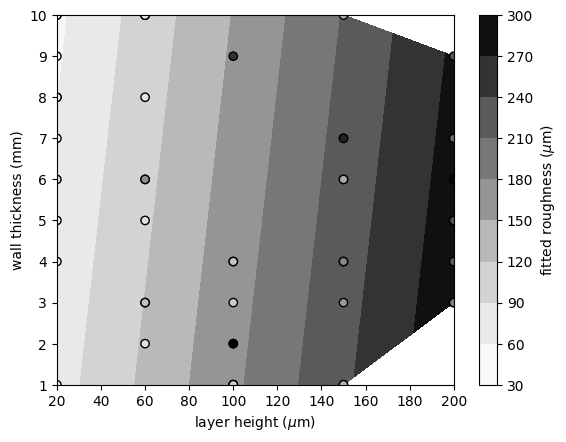

In [17]:
fig, ax = plt.subplots()
cs = ax.tricontourf(layer_um, wall, roughness_fit, cmap='Greys')
ax.scatter(layer_um, wall, c=roughness, cmap='Greys', edgecolor='k')
cb = fig.colorbar(cs, ax=ax)
cb.set_label('fitted roughness ($\\mu$m)')
ax.set_xlabel('layer height ($\\mu$m)')
ax.set_ylabel('wall thickness (mm)')

The nearly vertical bands show that fitted roughness changes mainly along the layer-height axis.
A marker whose shade differs from the band behind it has a residual, and the RMSE summarizes the sizes of those residuals.

To compare the two inputs, we multiply each coefficient by the span of its input in our data.

In [18]:
layer_span = np.max(layer_um) - np.min(layer_um)
wall_span = np.max(wall) - np.min(wall)

print(f'layer height, over {layer_span:.0f} um: {b_fit * layer_span:.0f} um of roughness')
print(f'wall thickness, over {wall_span:.0f} mm: {c_fit * wall_span:.0f} um of roughness')

layer height, over 180 um: 218 um of roughness
wall thickness, over 9 mm: -23 um of roughness


Across the sampled range, the fitted wall-thickness contribution is smaller than the typical miss of the fit.

The positive layer-height coefficient is consistent with stair-stepping.
Thicker deposited layers tend to give rougher side walls.

# Summary

On plotting two inputs:
* `ax.tricontourf(x, y, z)` fills bands of equal $z$ over scattered points, and `ax.scatter(..., c=z)` puts the measured values on top.
* The bands of a plane are straight and parallel.

On fitting a plane:
* A plane has three parameters, $z = a + b x + c y$, so the objective unpacks `a, b, c = params` and `x0` has three entries.
* The steps are the ones we used for a line: write the form, write the objective, call `minimize`, and score the residuals.
* Noise makes the bands of the data uneven, and the bands of the fitted plane are straight.
  The RMSE is close to the size of the noise.

On reading the coefficients:
* `b` and `c` are the change in `z` per unit of each input, in the units of `z` over the units of the input.
* A coefficient times the span of its input gives the change in `z` across our data.

The answer to our question about the printed walls: in this table, each additional micron of layer height corresponds to about 1.2 $\mu$m more roughness in the fitted plane.
Across the sampled wall-thickness range, its fitted contribution is smaller than the typical miss of the fit.

## Further reading

* Kong, Siauw, and Bayen, *Python Programming and Numerical Methods*, [Chapter 16, "Least Squares Regression"](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter16.00-Least-Squares-Regression.html)
* [`matplotlib.axes.Axes.tricontourf` documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.tricontourf.html)
* [`scipy.optimize.minimize` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)
* The printer data: Okudan, A. [3D printer dataset](https://github.com/ahmetokudan/3dprinterdeeplearning), unrestricted use
* Photo credit: RepRap printing close-up, Emmanuel Gilloz, [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/), [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:RepRap_printing_closeup.jpg)

# Appendix A: One more term

Optional.
A term $d\,x\,y$ makes the effect of layer height depend on wall thickness:

$$z = a + b\,x + c\,y + d\,x\,y$$

We fit it with four parameters, and `x0` has four entries.

In [19]:
def plane_xy(x, y, a, b, c, d):
    return a + b * x + c * y + d * x * y

def mse_plane_xy(params):
    a, b, c, d = params
    residuals = roughness - plane_xy(layer_um, wall, a, b, c, d)
    return np.mean(residuals**2)

res_xy = optimize.minimize(mse_plane_xy, [60, 1, -3, 0.01])
print(f'RMSE of the plane = {rmse(roughness, roughness_fit):.1f} um')
print(f'RMSE with the extra term = {np.sqrt(res_xy.fun):.1f} um')

RMSE of the plane = 58.2 um
RMSE with the extra term = 57.8 um


The RMSE barely changes, so we leave the extra parameter out.
Four parameters also make the coefficients harder to read.